# LCR & NSFR Engine with Stressed Outflows

In March 2023 Silicon Valley Bank lost a quarter of its deposits in a single day, far more than any regulatory run-off rate assumes. Liquidity ratios are only as good as the weights behind them. This notebook computes the Basel liquidity ratios exactly as the rules prescribe and then asks how the same balance sheet behaves under increasingly severe deposit runs.

**What it does.** It builds a $120bn U.S. regional bank balance sheet in the shape of the aggregate U.S. banking system.

It computes the Basel III Liquidity Coverage Ratio (HQLA by level with haircuts and caps, outflow and inflow rates, the 75% inflow cap) and the Net Stable Funding Ratio (ASF and RSF factors).

It then stresses liquidity day by day over 30 days under three scenarios: the regulatory scenario, a Monte Carlo deposit-run model calibrated to 40 years of weekly H.8 deposit data, and an SVB-style run on uninsured deposits.

**Data.** H.8 weekly balance-sheet aggregates of all commercial banks and of small domestically chartered banks (FRED). The bank's balance sheet is synthetic, scaled to those shares.

**Methods.** The Basel III LCR (BCBS 238) and NSFR (BCBS 295) rules, the HQLA cap adjustment, and an AR(1)–GARCH(1,1) model with Student-t errors for weekly deposit growth (arch).

A Monte Carlo of correlated run-offs by category gives the survival horizon with and without discount-window capacity, and a tornado chart shows the LCR's sensitivity to each run-off assumption.

**Key output.** LCR and NSFR with their components, survival days by scenario, the distribution of 30-day liquidity shortfalls, and the assumptions that move the LCR most.

## 1. Why liquidity metrics, and why stress them

The LCR asks whether a bank's **high-quality liquid assets** cover 30 days of stressed net cash outflows; the NSFR whether its **stable funding** covers the assets that need funding for a year. Both are ratios of regulatory weights applied to the balance sheet, so the real risk sits in the weights.

In March 2023 Silicon Valley Bank lost a quarter of its deposits in one day, far beyond any LCR run-off rate, and its HQLA was largely held-to-maturity securities that could not be sold without crystallising losses.

For a counterparty-risk function this matters twice. A bank counterparty's reported LCR says little about how long it survives a run, and the funding mix (insured retail vs uninsured corporate) decides that much more than the headline ratio. The notebook therefore computes the ratios exactly as the rules prescribe, then asks how the same balance sheet behaves under three increasingly severe deposit runs.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from arch import arch_model
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

BANK_ASSETS = 120.0  # $bn, a mid-size U.S. regional bank
START = "1985-01-01"
HORIZON_DAYS = 30
N_SIMS = 20_000
SEED = 23

import arch

print(f"arch {arch.__version__} · run on {dt.date.today():%Y-%m-%d}")

arch 8.0.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


SCEN_COLORS = {
    "Basel LCR scenario": PALETTE[0],
    "Historical-calibrated run (99th pct)": PALETTE[3],
    "SVB-style run": PALETTE[7],
}

## 3. Data: the shape of the U.S. banking system

The H.8 release gives weekly balance-sheet aggregates. Their latest shares set the bank's asset and liability mix: cash, securities, loans, deposits, large time deposits and borrowings as a share of total assets.

In [3]:
H8 = {
    "TLAACBW027SBOG": "total assets",
    "CASACBW027SBOG": "cash",
    "SBCACBW027SBOG": "securities",
    "TOTLL": "loans",
    "DPSACBW027SBOG": "deposits",
    "LTDACBW027SBOG": "large time deposits",
    "H8B3094NCBA": "borrowings",
    "DPSSCBW027SBOG": "small-bank deposits",
    "DPSLCBW027SBOG": "large-bank deposits",
}


def fetch_h8():
    return (
        pd.DataFrame({
            name: fred.get_series(sid, observation_start=START)
            for sid, name in H8.items()
        })
        .rename_axis("date")
        .reset_index()
    )


h8 = cached("fred_h8", fetch_h8).set_index("date")
h8.index = pd.to_datetime(h8.index)
# H8B3094NCBA is published in $ millions; the other H.8 series in $ billions
h8["borrowings"] = h8["borrowings"] / 1_000
latest = h8.dropna().iloc[-1]
shares = (
    latest[[
        "cash",
        "securities",
        "loans",
        "deposits",
        "large time deposits",
        "borrowings",
    ]]
    / latest["total assets"]
)
print(f"H.8 as of {h8.dropna().index[-1]:%Y-%m-%d}")
(shares * 100).round(1).to_frame("% of total assets").T

H.8 as of 2026-10-07


,cash,securities,loans,deposits,large time deposits,borrowings
% of total assets,12.30,22.10,54.30,75.80,10.00,9.20


## 4. The bank's balance sheet

Totals follow the H.8 shares. The split within each total follows typical regional-bank disclosures and is an explicit assumption in the table below (for example, 45% of securities in Treasuries, 40% in agency MBS). Deposits are split into the LCR categories. Operational and non-operational corporate deposits, deposits of financial institutions and large time deposits are treated as **uninsured**, which puts the uninsured share at about 45% of deposits, in line with U.S. regional banks before 2023.

In [4]:
A = BANK_ASSETS
cash = A * shares["cash"]
secs = A * shares["securities"]
loans = A * shares["loans"]
deps = A * shares["deposits"]
borr = A * shares["borrowings"]
ltd = A * shares["large time deposits"]
other_assets = A - cash - secs - loans
equity = 0.10 * A
other_liab = A - deps - borr - equity

assets = pd.DataFrame(
    [
        # name, $bn, HQLA level, LCR haircut, inflow (30d) rate, NSFR RSF
        # factor
        ("Reserves at the Fed", cash, "L1", 0.00, 0.00, 0.00),
        ("U.S. Treasuries", secs * 0.45, "L1", 0.00, 0.00, 0.05),
        ("Agency MBS", secs * 0.40, "L2A", 0.15, 0.00, 0.15),
        (
            "Municipal & IG corporate bonds",
            secs * 0.10,
            "L2B",
            0.50,
            0.00,
            0.50,
        ),
        ("Other securities (non-HQLA)", secs * 0.05, "", 1.00, 0.00, 0.85),
        ("Residential mortgages", loans * 0.30, "", 1.00, 0.01, 0.65),
        ("Consumer & card loans", loans * 0.15, "", 1.00, 0.04, 0.85),
        ("C&I loans", loans * 0.30, "", 1.00, 0.03, 0.85),
        ("Commercial real estate", loans * 0.25, "", 1.00, 0.01, 0.85),
        ("Other assets", other_assets, "", 1.00, 0.00, 1.00),
    ],
    columns=["item", "amount", "hqla", "haircut", "inflow", "rsf"],
)

retail = deps - ltd
dep_cats = {
    # name: (share of deposits ex large time, LCR 30-day run-off, NSFR ASF
    # factor, uninsured?)
    "Retail stable (insured)": (0.36, 0.03, 0.95, False),
    "Retail less stable": (0.18, 0.10, 0.90, False),
    "Small business": (0.08, 0.10, 0.90, False),
    "Operational (corporate)": (0.14, 0.25, 0.50, True),
    "Non-operational corporate": (0.18, 0.40, 0.50, True),
    "Financial institutions": (0.06, 1.00, 0.00, True),
}
liab_rows = [(k, retail * v[0], v[1], v[2], v[3]) for k, v in dep_cats.items()]
liab_rows += [
    ("Large time deposits (>30d)", ltd, 0.00, 0.50, True),
    ("FHLB advances > 1y", borr * 0.6, 0.00, 1.00, False),
    ("Repo & short borrowings < 30d", borr * 0.4, 0.25, 0.00, False),
    ("Other liabilities", other_liab, 0.00, 0.00, False),
    ("Equity", equity, 0.00, 1.00, False),
]
liabs = pd.DataFrame(
    liab_rows, columns=["item", "amount", "runoff", "asf", "uninsured"]
)
off_bs = pd.DataFrame(
    [
        ("Undrawn retail credit lines", 0.06 * A, 0.05, 0.05),
        ("Undrawn committed corporate facilities", 0.10 * A, 0.10, 0.05),
        ("Liquidity facilities to financials", 0.02 * A, 0.40, 0.05),
    ],
    columns=["item", "amount", "runoff", "rsf"],
)
uninsured_dep = liabs.loc[
    liabs["uninsured"] & liabs["item"].ne("Equity"), "amount"
].sum()
print(
    f"Assets ${A:.0f}bn · deposits ${deps:.1f}bn ({deps / A:.0%}) · uninsured"
    f" ${uninsured_dep:.1f}bn ({uninsured_dep / deps:.0%} of deposits) ·"
    f" equity ${equity:.0f}bn"
)
pd.concat({
    "assets": assets.set_index("item")[["amount", "hqla", "haircut"]],
    "liabilities": liabs.set_index("item")[["amount", "runoff"]],
}).round(2)

Assets $120bn · deposits $90.9bn (76%) · uninsured $42.0bn (46% of deposits) · equity $12bn


amount hqla  haircut  runoff
            item                                                        
assets      Reserves at the Fed              14.75   L1     0.00     NaN
            U.S. Treasuries                  11.93   L1     0.00     NaN
            Agency MBS                       10.60  L2A     0.15     NaN
            Municipal & IG corporate bonds    2.65  L2B     0.50     NaN
            Other securities (non-HQLA)       1.33          1.00     NaN
            Residential mortgages            19.56          1.00     NaN
            Consumer & card loans             9.78          1.00     NaN
            C&I loans                        19.56          1.00     NaN
            Commercial real estate           16.30          1.00     NaN
            Other assets                     13.53          1.00     NaN
liabilities Retail stable (insured)          28.41  NaN      NaN    0.03
            Retail less stable               14.21  NaN      NaN    0.10
            Small business                    6.31  NaN      NaN    0.10
            Operational (corporate)          11.05  NaN      NaN    0.25
            Non-operational corporate        14.21  NaN      NaN    0.40
            Financial institutions            4.74  NaN      NaN    1.00
            Large time deposits (>30d)       11.98  NaN      NaN    0.00
            FHLB advances > 1y                6.59  NaN      NaN    0.00
            Repo & short borrowings < 30d     4.40  NaN      NaN    0.25
            Other liabilities                 6.11  NaN      NaN    0.00
            Equity                           12.00  NaN      NaN    0.00

## 5. LCR and NSFR

**LCR** $= \text{HQLA} / \text{net outflows}_{30d}$, with:
- HQLA after haircuts (Level 1 0%, 2A 15%, 2B 50%), Level 2 at most 40% and Level 2B at most 15% of the stock (the adjusted-stock formula of BCBS 238 §48);
- net outflows = outflows − min(inflows, 75% of outflows).

**NSFR** $= \text{ASF}/\text{RSF}$, the weighted sums of available and required stable funding. Both must be at least 100%.

In [5]:
def hqla_stock(a):
    l1 = a.loc[a["hqla"] == "L1", "amount"].sum()
    l2a = (
        a.loc[a["hqla"] == "L2A", "amount"]
        * (1 - a.loc[a["hqla"] == "L2A", "haircut"])
    ).sum()
    l2b = (
        a.loc[a["hqla"] == "L2B", "amount"]
        * (1 - a.loc[a["hqla"] == "L2B", "haircut"])
    ).sum()
    # caps: L2B ≤ 15/85 of (L1 + L2A); total L2 ≤ 2/3 of L1
    l2b_c = min(l2b, 15 / 85 * (l1 + l2a))
    l2_c = min(l2a + l2b_c, 2 / 3 * l1)
    return l1 + l2_c, {
        "Level 1": l1,
        "Level 2A (after haircut, capped)": min(l2a, l2_c),
        "Level 2B (after haircut, capped)": (
            max(l2_c - l2a, 0) if l2_c > l2a else 0
        ),
    }


def lcr(a, l, ob, runoff_scale=None):
    runoff_scale = runoff_scale or {}
    out_dep = (
        l["amount"]
        * l["runoff"]
        * l["item"].map(lambda k: runoff_scale.get(k, 1.0))
    ).sum()
    out_ob = (
        ob["amount"]
        * ob["runoff"]
        * ob["item"].map(lambda k: runoff_scale.get(k, 1.0))
    ).sum()
    inflows = (a["amount"] * a["inflow"]).sum()
    outflows = out_dep + out_ob
    net = outflows - min(inflows, 0.75 * outflows)
    hq, parts = hqla_stock(a)
    return hq / net, {
        "HQLA": hq,
        **parts,
        "Deposit & funding outflows": out_dep,
        "Off-balance-sheet outflows": out_ob,
        "Inflows (capped)": min(inflows, 0.75 * outflows),
        "Net outflows": net,
    }


def nsfr(a, l, ob):
    asf = (l["amount"] * l["asf"]).sum()
    rsf = (a["amount"] * a["rsf"]).sum() + (ob["amount"] * ob["rsf"]).sum()
    return asf / rsf, asf, rsf


LCR, lcr_parts = lcr(assets, liabs, off_bs)
NSFR, ASF, RSF = nsfr(assets, liabs, off_bs)
print(f"LCR {LCR:.0%} · NSFR {NSFR:.0%} (ASF ${ASF:.1f}bn / RSF ${RSF:.1f}bn)")
pd.Series(lcr_parts).round(2).to_frame("$bn")

LCR 202% · NSFR 117% (ASF $82.7bn / RSF $70.8bn)


,$bn
HQLA,37.02
Level 1,26.68
"Level 2A (after haircut, capped)",9.01
"Level 2B (after haircut, capped)",1.33
Deposit & funding outflows,17.18
Off-balance-sheet outflows,2.52
Inflows (capped),1.34
Net outflows,18.37


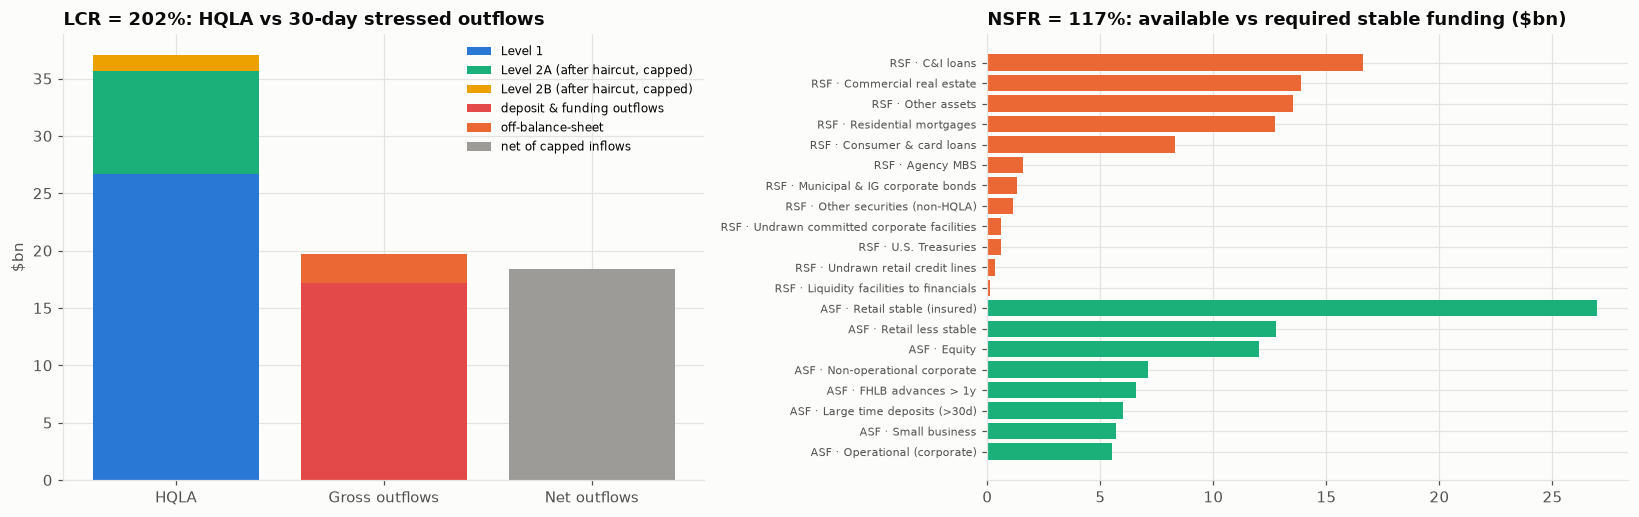

In [6]:
# --- Chart 1: LCR and NSFR composition
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
items = [
    "Level 1",
    "Level 2A (after haircut, capped)",
    "Level 2B (after haircut, capped)",
]
bottom = 0
for k, c in zip(items, [PALETTE[0], PALETTE[2], PALETTE[3]]):
    ax.bar("HQLA", lcr_parts[k], bottom=bottom, color=c, label=k)
    bottom += lcr_parts[k]
ax.bar(
    "Gross outflows",
    lcr_parts["Deposit & funding outflows"],
    color=PALETTE[7],
    label="deposit & funding outflows",
)
ax.bar(
    "Gross outflows",
    lcr_parts["Off-balance-sheet outflows"],
    bottom=lcr_parts["Deposit & funding outflows"],
    color=PALETTE[1],
    label="off-balance-sheet",
)
ax.bar(
    "Net outflows",
    lcr_parts["Net outflows"],
    color="#9c9b97",
    label="net of capped inflows",
)
ax.set_ylabel("$bn")
ax.set_title(f"LCR = {LCR:.0%}: HQLA vs 30-day stressed outflows")
ax.legend(fontsize=8)
ax = axes[1]
asf_by = (
    liabs.set_index("item")["amount"] * liabs.set_index("item")["asf"]
).sort_values()
rsf_by = pd.concat([
    (assets.set_index("item")["amount"] * assets.set_index("item")["rsf"]),
    (off_bs.set_index("item")["amount"] * off_bs.set_index("item")["rsf"]),
]).sort_values()
ax.barh(
    [f"ASF · {k}" for k in asf_by.index[asf_by > 0]],
    asf_by[asf_by > 0],
    color=PALETTE[2],
)
ax.barh(
    [f"RSF · {k}" for k in rsf_by.index[rsf_by > 0]],
    rsf_by[rsf_by > 0],
    color=PALETTE[1],
)
ax.set_title(f"NSFR = {NSFR:.0%}: available vs required stable funding ($bn)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
save_fig(fig, "01_lcr_nsfr_composition")
plt.show()

## 6. How fast do deposits actually move? A GARCH model of weekly deposit growth

The regulatory run-off rates are fixed. Real deposit flows have fat tails and volatility clustering: calm for years, then a week like March 2023. Weekly log growth of deposits at **small domestically chartered banks** (the H.8 category that contains regional banks) since 1986 (1985 contains series start-up breaks) is modelled as AR(1) with GARCH(1,1) volatility and Student-t errors.

Simulated four-week paths from the fitted model, started from a stressed volatility state, give the distribution of a month's deposit outflow at the system level.

In [7]:
# 1985 has series start-up breaks (−14%, +8% weeks)
g = (np.log(h8["small-bank deposits"]).diff() * 100).dropna().loc["1986":]
am = arch_model(
    g, mean="AR", lags=1, vol="GARCH", p=1, q=1, dist="t", rescale=False
)
res = am.fit(disp="off")
print(res.summary().tables[1])
worst_4w = g.rolling(4).sum().nsmallest(3)
print(
    "Worst 4-week deposit changes, small banks (%):",
    ", ".join(f"{d:%Y-%m-%d} {v:.2f}" for d, v in worst_4w.items()),
)

# Simulate 4-week paths from the 99th-percentile conditional volatility state
rng = np.random.default_rng(SEED)
params = res.params
mu, phi, omega, alpha, beta_g, nu = (
    params["Const"],
    params[
        next(
            k
            for k in params.index
            if k.endswith("[1]") and not k.startswith(("alpha", "beta"))
        )
    ],
    params["omega"],
    params["alpha[1]"],
    params["beta[1]"],
    params["nu"],
)
# the first value is NaN (AR lag)
sig2_0 = np.nanquantile(res.conditional_volatility**2, 0.99)
paths = np.zeros((N_SIMS, 4))
s2, prev = np.full(N_SIMS, sig2_0), np.full(N_SIMS, g.iloc[-1])
for w in range(4):
    z = stats.t.rvs(nu, size=N_SIMS, random_state=rng) * np.sqrt((nu - 2) / nu)
    eps = np.sqrt(s2) * z
    x = mu + phi * prev + eps
    paths[:, w] = x
    s2 = omega + alpha * eps**2 + beta_g * s2
    prev = x
# % change over 4 weeks
month_change = paths.sum(1)
q99 = np.quantile(month_change, 0.01)
print(
    "System-level 4-week deposit change from a stressed state: 1st pct"
    f" {q99:.2f}%, 0.1st pct {np.quantile(month_change, 0.001):.2f}%"
)

                                 Mean Model                                
                    coef    std err          t      P>|t|  95.0% Conf. Int.
---------------------------------------------------------------------------
Const             0.1474  1.056e-02     13.952  3.052e-44 [  0.127,  0.168]
smal...its[1]    -0.3027  3.570e-02     -8.478  2.296e-17 [ -0.373, -0.233]
Worst 4-week deposit changes, small banks (%): 2023-03-29 -4.20, 2023-03-22 -4.15, 2023-04-05 -3.58
System-level 4-week deposit change from a stressed state: 1st pct -4.31%, 0.1st pct -8.05%


## 7. Three 30-day stress scenarios

Each scenario produces **daily** outflows by category. The bank meets them first from cash, then by selling (or repo-ing) Level 1, then Level 2A and 2B at their haircuts. The **survival horizon** is the day the buffer runs out. A second horizon adds the discount window: loans can be pledged to the Fed at a 25% haircut, which is how banks bridged the March 2023 run.

| Scenario | Deposit behaviour |
|---|---|
| **Basel LCR scenario** | the regulatory 30-day run-off rates, spread evenly over 30 days |
| **Historical-calibrated run (99th pct)** | the GARCH system-level outflow at the 1st percentile, applied with category betas: insured retail moves 0.3× the system, uninsured corporate and financial 3× (uninsured money is the flighty part, as in 2023) |
| **SVB-style run** | uninsured deposits run 25% on day 1 and half of what is left on day 2 (SVB lost 25% of its deposits on 9 March 2023 and had requests for another 62% the next morning), then 10% a day for three days and 2% a day after; insured retail 2% over the month; short funding does not roll; committed facilities drawn at LCR rates. The securities in the buffer have also lost **10% of market value** (a 5-year duration book after a 200 bp rise, as in 2022), so selling or repo-ing them raises less cash |

In [8]:
CAT_BETA = {
    "Retail stable (insured)": 0.3,
    "Retail less stable": 0.8,
    "Small business": 1.0,
    "Operational (corporate)": 2.0,
    "Non-operational corporate": 3.0,
    "Financial institutions": 3.0,
    "Large time deposits (>30d)": 1.0,
}


def daily_outflows(scenario, system_month=None):
    """Matrix [day, category] of outflows in $bn."""
    out = {}
    for _, r in liabs.iterrows():
        k, amt = r["item"], r["amount"]
        if scenario == "Basel LCR scenario":
            total = amt * r["runoff"]
            out[k] = np.full(HORIZON_DAYS, total / HORIZON_DAYS)
        elif scenario.startswith("Historical"):
            rate = (
                min(1.0, -system_month / 100 * CAT_BETA.get(k, 0.0))
                if k in CAT_BETA
                else (r["runoff"] if "Repo" in k else 0)
            )
            out[k] = np.full(HORIZON_DAYS, amt * rate / HORIZON_DAYS)
        # SVB-style
        else:
            if r["uninsured"] and k != "Large time deposits (>30d)":
                left, flows = amt, []
                for d in range(HORIZON_DAYS):
                    rate = (
                        0.25
                        if d == 0
                        else 0.50 if d == 1 else 0.10 if d < 5 else 0.02
                    )
                    f = left * rate
                    flows.append(f)
                    left -= f
                out[k] = np.array(flows)
            elif k.startswith("Retail") or k == "Small business":
                out[k] = np.full(HORIZON_DAYS, amt * 0.02 / HORIZON_DAYS)
            elif "Repo" in k:
                # short funding does not roll
                out[k] = np.r_[amt, np.zeros(HORIZON_DAYS - 1)]
            else:
                out[k] = np.zeros(HORIZON_DAYS)
    for _, r in off_bs.iterrows():
        out[r["item"]] = np.full(
            HORIZON_DAYS, r["amount"] * r["runoff"] / HORIZON_DAYS
        )
    return pd.DataFrame(out)


# unrealised loss on HQLA securities in the scenario
SECURITIES_LOSS = {"SVB-style run": 0.10}


def survival(flows, with_discount_window=False, securities_loss=0.0):
    """
    Day on which cumulative outflows exceed the liquidity buffer (None =
    survives 30 days).
    """
    layers = [
        lcr_parts["Level 1"],
        lcr_parts["Level 2A (after haircut, capped)"],
        lcr_parts["Level 2B (after haircut, capped)"],
    ]
    reserves = assets.loc[
        assets["item"] == "Reserves at the Fed", "amount"
    ].sum()
    buffer = (
        sum(layers)
        - securities_loss * (sum(layers) - reserves)
        + (
            assets.loc[
                assets["item"].str.contains(
                    "loans|mortgages|estate", case=False
                ),
                "amount",
            ].sum()
            * 0.75
            if with_discount_window
            else 0
        )
    )
    cum = flows.sum(axis=1).cumsum()
    breach = np.flatnonzero(cum.to_numpy() > buffer)
    return (int(breach[0]) + 1 if len(breach) else None), cum, buffer


scen_flows = {
    "Basel LCR scenario": daily_outflows("Basel LCR scenario"),
    "Historical-calibrated run (99th pct)": daily_outflows("Historical", q99),
    "SVB-style run": daily_outflows("SVB-style run"),
}
rows = {}
for name, fl in scen_flows.items():
    loss = SECURITIES_LOSS.get(name, 0.0)
    d1, cum, buf = survival(fl, securities_loss=loss)
    d2, _, buf2 = survival(fl, True, securities_loss=loss)
    rows[name] = {
        "30-day outflow $bn": cum.iloc[-1],
        "outflow % of deposits": cum.iloc[-1] / deps * 100,
        "HQLA buffer $bn": buf,
        "survival days (HQLA only)": d1 or f">{HORIZON_DAYS}",
        "survival days (+ discount window)": d2 or f">{HORIZON_DAYS}",
        "day-1 outflow $bn": fl.iloc[0].sum(),
    }
scen_table = pd.DataFrame(rows).T
scen_table

,30-day outflow $bn,outflow % of deposits,HQLA buffer $bn,survival days (HQLA only),survival days (+ discount window),day-1 outflow $bn
Basel LCR scenario,19.70,21.68,37.02,>30,>30,0.66
Historical-calibrated run (99th pct),8.67,9.54,37.02,>30,>30,0.29
SVB-style run,32.94,36.23,34.79,>30,>30,12.01


### Monte Carlo of the historical-calibrated run

The single 99th-percentile scenario hides the distribution. Each of 20,000 GARCH paths gives a system outflow; category outflows add an idiosyncratic multiplier (log-normal, 30% dispersion) so that the categories do not move in lock-step. The result is a distribution of the 30-day liquidity surplus or shortfall.

In [9]:
mult = np.exp(rng.normal(-0.045, 0.3, size=(N_SIMS, len(CAT_BETA))))
cat_amt = np.array(
    [liabs.set_index("item").loc[k, "amount"] for k in CAT_BETA]
)
betas = np.array(list(CAT_BETA.values()))
dep_out = (
    np.clip(-month_change[:, None] / 100 * betas[None, :] * mult, -0.2, 1.0)
    @ cat_amt
)
fixed_out = (
    liabs.loc[liabs["item"].str.contains("Repo"), "amount"].sum() * 0.25
    + (off_bs["amount"] * off_bs["runoff"]).sum()
)
buffer = lcr_parts["HQLA"]
surplus = buffer - (dep_out + fixed_out)
p_short = (surplus < 0).mean()
print(
    f"P(30-day outflows exceed HQLA) = {p_short:.2%} · 1st pct surplus"
    f" ${np.quantile(surplus, 0.01):.1f}bn · median surplus"
    f" ${np.median(surplus):.1f}bn"
)

P(30-day outflows exceed HQLA) = 0.00% · 1st pct surplus $28.3bn · median surplus $33.9bn


## 8. Which assumption moves the LCR? A tornado

Each run-off (or haircut) assumption is moved by ±50% of its value, one at a time, and the LCR recomputed. The widest bars are the assumptions a validator should challenge first, and the categories where a counterparty's disclosure matters most.

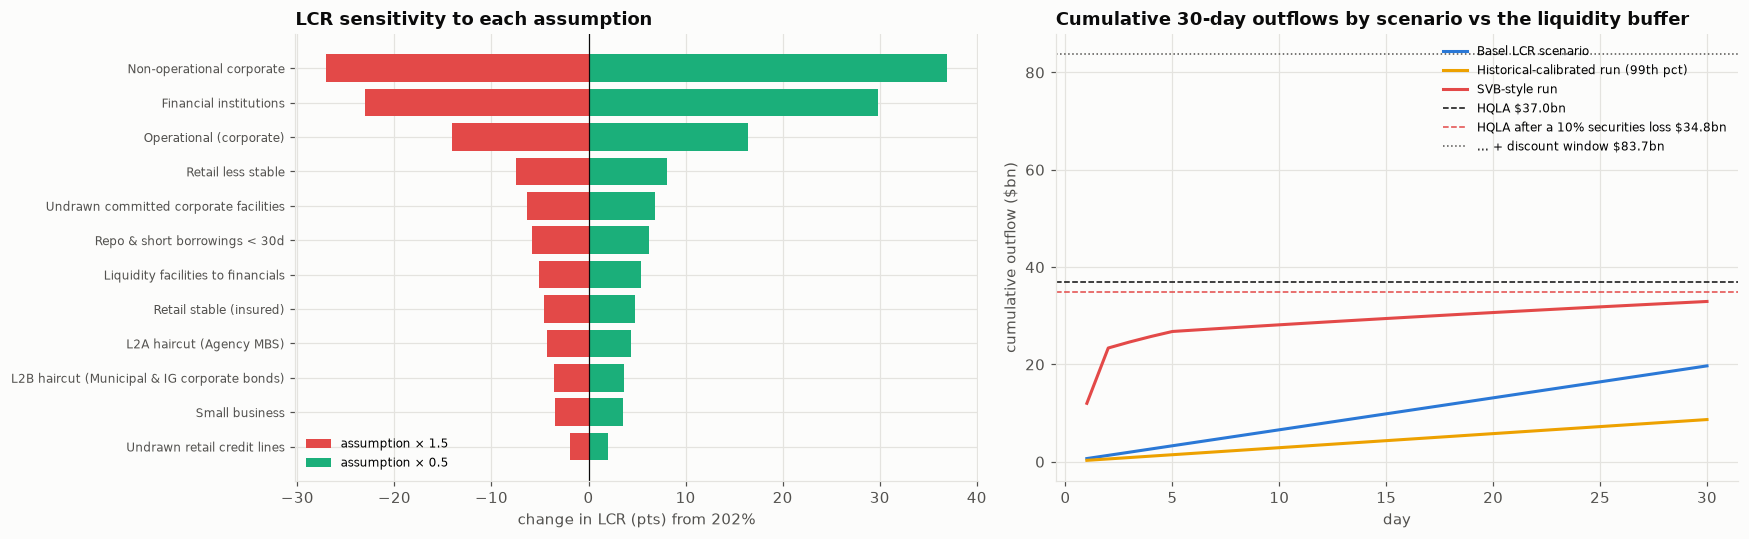

,LCR at 0.5×,LCR at 1.5×,range (pts)
Undrawn retail credit lines,2.04,2.00,3.95
Small business,2.05,1.98,6.93
L2B haircut (Municipal & IG corporate bonds),2.05,1.98,7.22
L2A haircut (Agency MBS),2.06,1.97,8.66
Retail stable (insured),2.06,1.97,9.36
Liquidity facilities to financials,2.07,1.96,10.54
Repo & short borrowings < 30d,2.08,1.96,12.07
Undrawn committed corporate facilities,2.08,1.95,13.18
Retail less stable,2.10,1.94,15.61
Operational (corporate),2.18,1.88,30.49


In [10]:
tornado = {}
for k in (
    list(dep_cats)
    + ["Repo & short borrowings < 30d"]
    + off_bs["item"].tolist()
):
    lo, _ = lcr(assets, liabs, off_bs, {k: 0.5})
    hi, _ = lcr(assets, liabs, off_bs, {k: 1.5})
    tornado[k] = (lo, hi)
for lvl, col in [
    ("L2A", "Agency MBS"),
    ("L2B", "Municipal & IG corporate bonds"),
]:
    a2 = assets.copy()
    base_h = a2.loc[a2["item"] == col, "haircut"].iloc[0]
    out = []
    for f in (0.5, 1.5):
        a2.loc[a2["item"] == col, "haircut"] = min(base_h * f, 1.0)
        out.append(lcr(a2, liabs, off_bs)[0])
    tornado[f"{lvl} haircut ({col})"] = (out[0], out[1])
tor = pd.DataFrame(tornado, index=["LCR at 0.5×", "LCR at 1.5×"]).T
tor["range (pts)"] = (tor["LCR at 0.5×"] - tor["LCR at 1.5×"]).abs() * 100
tor = tor.sort_values("range (pts)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.barh(
    tor.index,
    (tor["LCR at 1.5×"] - LCR) * 100,
    color=PALETTE[7],
    label="assumption × 1.5",
)
ax.barh(
    tor.index,
    (tor["LCR at 0.5×"] - LCR) * 100,
    color=PALETTE[2],
    label="assumption × 0.5",
)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel(f"change in LCR (pts) from {LCR:.0%}")
ax.set_title("LCR sensitivity to each assumption")
ax.legend(fontsize=8)
ax.tick_params(axis="y", labelsize=8)
ax = axes[1]
for name, fl in scen_flows.items():
    _, cum, buf = survival(fl)
    ax.plot(
        np.arange(1, HORIZON_DAYS + 1),
        cum,
        color=SCEN_COLORS[name],
        lw=2,
        label=name,
    )
_, _, buf_svb = survival(scen_flows["SVB-style run"], securities_loss=0.10)
_, _, buf_dw = survival(
    scen_flows["SVB-style run"], True, securities_loss=0.10
)
ax.axhline(
    lcr_parts["HQLA"],
    color=INK,
    ls="--",
    lw=1,
    label=f"HQLA ${lcr_parts['HQLA']:.1f}bn",
)
ax.axhline(
    buf_svb,
    color=PALETTE[7],
    ls="--",
    lw=1,
    label=f"HQLA after a 10% securities loss ${buf_svb:.1f}bn",
)
ax.axhline(
    buf_dw,
    color=INK_2,
    ls=":",
    lw=1,
    label=f"... + discount window ${buf_dw:.1f}bn",
)
ax.set_xlabel("day")
ax.set_ylabel("cumulative outflow ($bn)")
ax.set_title("Cumulative 30-day outflows by scenario vs the liquidity buffer")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_tornado_and_survival")
plt.show()
tor.round(3)

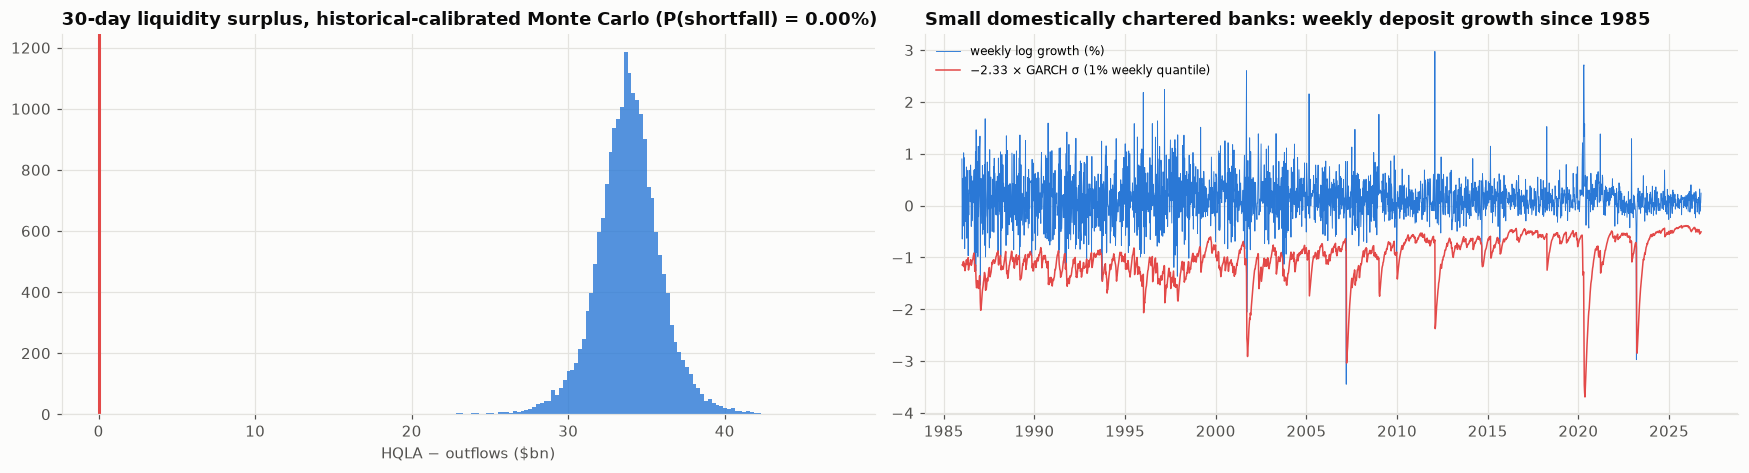

In [11]:
# --- Chart 3: Monte Carlo surplus distribution and the deposit history
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))
ax = axes[0]
ax.hist(surplus, bins=120, color=PALETTE[0], alpha=0.8)
ax.axvline(0, color=PALETTE[7], lw=2)
ax.set_title(
    "30-day liquidity surplus, historical-calibrated Monte Carlo"
    f" (P(shortfall) = {p_short:.2%})"
)
ax.set_xlabel("HQLA − outflows ($bn)")
ax = axes[1]
ax.plot(g.index, g, color=PALETTE[0], lw=0.6, label="weekly log growth (%)")
ax.plot(
    res.conditional_volatility.index,
    -2.33 * res.conditional_volatility,
    color=PALETTE[7],
    lw=1,
    label="−2.33 × GARCH σ (1% weekly quantile)",
)
ax.set_title(
    "Small domestically chartered banks: weekly deposit growth since 1985"
)
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "03_monte_carlo_and_deposit_history")
plt.show()
scen_table.to_csv(OUT_DIR / "scenario_survival.csv")
tor.to_csv(OUT_DIR / "lcr_tornado.csv")
pd.concat({
    "assets": assets.set_index("item"),
    "liabilities": liabs.set_index("item"),
}).to_csv(OUT_DIR / "balance_sheet.csv")
pd.Series({
    "LCR": LCR,
    "NSFR": NSFR,
    **lcr_parts,
    "ASF": ASF,
    "RSF": RSF,
    "P(MC shortfall)": p_short,
}).to_csv(OUT_DIR / "ratios.csv")

## 9. Reading the results and limitations

A $120bn regional bank in the shape of the aggregate U.S. banking system (H.8, 7 October 2026), 46% of deposits uninsured:

**The ratios pass comfortably.** The LCR is **202%**: $37.0bn of HQLA (72% Level 1: reserves and Treasuries; $9.0bn Level 2A agency MBS after the 15% haircut; $1.3bn Level 2B) against $18.4bn of net 30-day outflows. The NSFR is **117%** ($82.7bn of available against $70.8bn of required stable funding). That reflects today's system: banks hold about 12% of assets in cash and 22% in securities.

**The LCR rests on a few run-off assumptions.** In the tornado, moving one assumption by ±50% shifts the LCR by up to 64 points. The widest bars are non-operational corporate deposits (40% run-off), deposits of financial institutions (100%) and operational deposits (25%): exactly the uninsured, wholesale money that left SVB, Signature and First Republic. Insured retail barely matters (9 points). A validator should challenge the categorisation of corporate deposits first.

**History-calibrated runs are much milder than the rules.** The AR(1)–GARCH-t model of weekly small-bank deposit growth (1986–2026) puts the worst four weeks on record at −4.2% (late March 2023). Started from a stressed volatility state, its 1st percentile for a month is −4.3%, and the 0.1st percentile −8.1%.

Translated to this bank with category betas, the 99th-percentile run takes $8.7bn (10% of deposits), less than half the Basel scenario ($19.7bn, 22%). Across 20,000 Monte Carlo paths the buffer is never exhausted (1st-percentile surplus $28bn). The LCR is deliberately more severe than system-level history.

**An SVB-style run is the scenario that bites.** With uninsured deposits running 25% on day 1 and half of the rest on day 2, and a 10% loss on the securities in the buffer, the bank loses **$32.9bn in 30 days (36% of deposits), $12bn on the first day**, against a buffer of $34.8bn. It survives the month, but with only $1.9bn to spare, and the discount window (loans pledged at a 25% haircut) is what turns a near-miss into a comfortable survival.

SVB failed because it had far less HQLA relative to uninsured deposits and larger unrealised losses on securities, which it could not sell without crystallising them.

- **For a counterparty analyst,** the reading is that the LCR is a necessary but not sufficient signal. The same LCR can hide very different exposure to uninsured, concentrated deposits. Survival horizons under an SVB-type run, and the share of HQLA held at amortised cost, should sit next to the ratio in a bank counterparty review.

**Limitations**

- The balance sheet is synthetic: H.8 aggregates fix the totals, and the split within categories is an assumption shown in the tables.
- Run-off is applied evenly or with fixed day-1 shocks. Real runs are faster and concentrated in a few large depositors, which a depositor-level model would capture.
- The securities loss is a single scenario value, not a revaluation of the bank's actual portfolio, and the discount window is assumed available on day 1 with a uniform 25% haircut.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2013). *Basel III: The liquidity coverage ratio and liquidity risk monitoring tools* (BCBS 238). Bank for International Settlements. https://www.bis.org/publ/bcbs238.htm
- Basel Committee on Banking Supervision. (2014). *Basel III: The net stable funding ratio* (BCBS 295). Bank for International Settlements. https://www.bis.org/bcbs/publ/d295.htm
- Board of Governors of the Federal Reserve System. (2023). *Review of the Federal Reserve's supervision and regulation of Silicon Valley Bank*. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Cipriani, M., Eisenbach, T. M., & Kovner, A. (2024). *Tracing bank runs in real time* (Staff Report No. 1104). Federal Reserve Bank of New York. https://doi.org/10.59576/sr.1104
- Diamond, D. W., & Dybvig, P. H. (1983). Bank runs, deposit insurance, and liquidity. *Journal of Political Economy, 91*(3), 401–419. https://doi.org/10.1086/261155

### Machine learning and deep learning

- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1
- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1